# Setup

In [3]:
import sys
sys.path.insert(0, '/home/seif/Desktop/PycharmProjects/AI&ML dbrouke course/fast_ai/Part_2/course22p2')
import os
os.environ['CUDA_VISIBLE_DEVICES']='1'
import pickle,gzip,math,os,time,shutil,torch,random,logging
import fastcore.all as fc,matplotlib as mpl,numpy as np,matplotlib.pyplot as plt
from collections.abc import Mapping
from pathlib import Path
from functools import partial

from fastcore.foundation import L
import torchvision.transforms.functional as TF,torch.nn.functional as F
from torch import tensor,nn,optim
from torch.utils.data import DataLoader,default_collate
from torch.nn import init
from torch.optim import lr_scheduler

from miniai.datasets import *
from miniai.conv import *
from miniai.learner import *
from miniai.activations import *
from miniai.init import *
from miniai.sgd import *
from miniai.resnet import *
from miniai.augment import *
from miniai.accel import *

from torcheval.metrics import MulticlassAccuracy
from datasets import load_dataset,load_dataset_builder

mpl.rcParams['image.cmap'] = 'gray_r'
logging.disable(logging.WARNING)

set_seed(42)
if fc.defaults.cpus>8: fc.defaults.cpus=8

In [4]:
import torch
torch.cuda.is_available()

True

In [5]:
xl,yl = 'image','label'
name = "fashion_mnist"
dsd = load_dataset(name)

@inplace
def transformi(b): b[xl] = [F.pad(TF.to_tensor(o), (2,2,2,2))-0.5 for o in b[xl]]

bs = 256
tds = dsd.with_transform(transformi)
dls = DataLoaders.from_dd(tds, bs, num_workers=8)

- here we have found out that making the the transform make the numbers [-0.5 -> 0.5] is made the results better than the classic [-1 -> 1]

# Scheds

In [6]:
# that just makes an object easier
from types import SimpleNamespace

In [7]:
def linear_sched(betamin=0.0001,betamax=0.02,n_steps=1000):
    beta = torch.linspace(betamin, betamax, n_steps)
    return SimpleNamespace(a=1.-beta, abar=(1.-beta).cumprod(dim=0), sig=beta.sqrt())

In [8]:
def abar(t, T): return (t / T * math.pi / 2).cos() ** 2

In [9]:
def cos_sched(n_steps=1000):
    ts = torch.linspace(0, n_steps - 1, n_steps)
    ab = abar(ts, n_steps)
    alp = ab / abar(ts - 1, n_steps)
    return SimpleNamespace(a=alp, abar=ab, sig=(1 - alp).sqrt())

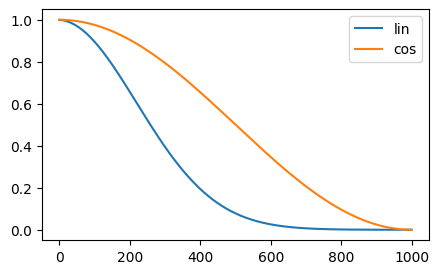

In [10]:
lin_abar = linear_sched().abar
cos_abar = cos_sched().abar
plt.figure(figsize=(5,3))
plt.plot(lin_abar, label='lin')
plt.plot(cos_abar, label='cos')
plt.legend();

- `abar` was the amount of the image not noise

We can see that the cosine scheduler is more uniform and at the late t(s) It is not flat as the linear with no change in abar

In [11]:
l = [3,4,5,6,7]
l[1:],l[:-1]

([4, 5, 6, 7], [3, 4, 5, 6])

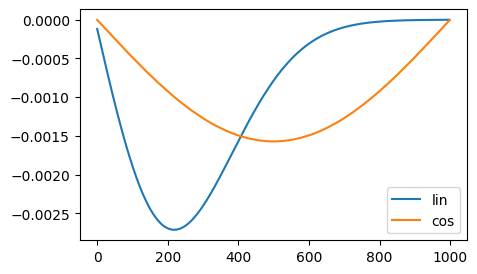

In [12]:
# plot the slope
plt.figure(figsize=(5,3))
plt.plot(lin_abar[1:] - lin_abar[:-1], label='lin')
plt.plot(cos_abar[1:] - cos_abar[:-1], label='cos')
plt.legend();

    abar = [1.0, 0.99, 0.98, 0.97, 0.96 ...]
        ↑     ↑     ↑
       t=0   t=1   t=2

    abar[1:] - abar[:-1] =
        abar[1]-abar[0] = 0.99-1.0  = -0.01
        abar[2]-abar[1] = 0.98-0.99 = -0.01
        abar[3]-abar[2] = 0.97-0.98 = -0.01
        ...

    = how much did abar change each step

we can see cosine is more uniform

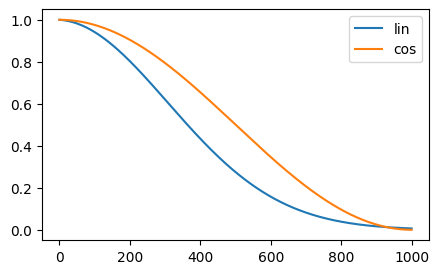

In [13]:
# make beta 0.01
plt.figure(figsize=(5,3))
lin_abar = linear_sched(betamax=0.01).abar
plt.plot(lin_abar, label='lin')
plt.plot(cos_abar, label='cos')
plt.legend();

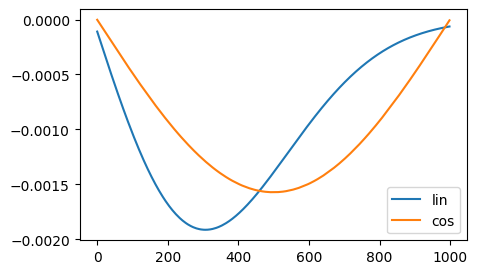

In [14]:
plt.figure(figsize=(5,3))
plt.plot(lin_abar[1:]-lin_abar[:-1], label='lin')
plt.plot(cos_abar[1:]-cos_abar[:-1], label='cos')
plt.legend();

Here by making the beta Halved both graphs become more similar

In [15]:
n_steps = 1000
lin_abar = linear_sched(betamax=0.01) # we made beta=0.01 (better from our experiments)
alphabar = lin_abar.abar
alpha = lin_abar.a
sigma = lin_abar.sig

In [16]:
def noisify(x0, ᾱ):
    device = x0.device
    n = len(x0)
    t = torch.randint(0, n_steps, (n,), dtype=torch.long)
    ε = torch.randn(x0.shape, device=device)
    ᾱ_t = ᾱ[t].reshape(-1, 1, 1, 1).to(device)
    xt = ᾱ_t.sqrt()*x0 + (1-ᾱ_t).sqrt()*ε
    return (xt, t.to(device)), ε

In [17]:
dt = dls.train
xb,yb = next(iter(dt))

In [18]:
(xt,t),ε = noisify(xb[:25],alphabar)
t

tensor([ 26, 335, 620, 924, 950, 113, 378,  14, 210, 954, 231, 572, 315, 295,
        567, 706, 749, 876,  73, 111, 899, 213, 541, 769, 287])

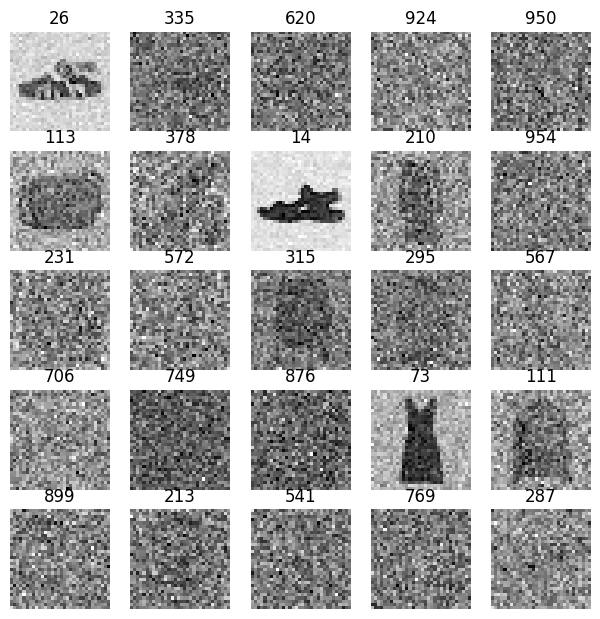

In [19]:
titles = fc.map_ex(t[:25], '{}')
show_images(xt[:25], imsize=1.5, titles=titles)

# Training

In [20]:
from diffusers import UNet2DModel
class UNet(UNet2DModel):
    def forward(self, x): return super().forward(*x).sample

In [21]:
def init_ddpm(model):
    for o in model.down_blocks:
        for p in o.resnets:
            p.conv2.weight.data.zero_()
            for p in fc.L(o.downsamplers): init.orthogonal_(p.conv.weight)

    for o in model.up_blocks:
        for p in o.resnets: p.conv2.weight.data.zero_()

    model.conv_out.weight.data.zero_()

In [22]:
def collate_ddpm(b): return noisify(default_collate(b)[xl], alphabar)
def dl_ddpm(ds, nw=4): return DataLoader(ds, batch_size=bs, collate_fn=collate_ddpm, num_workers=nw)

In [23]:
dls = DataLoaders(dl_ddpm(tds['train']), dl_ddpm(tds['test']))

In [24]:
lr = 1e-2
epochs = 25
opt_func = partial(optim.AdamW, eps=1e-5)
tmax = epochs * len(dls.train)
sched = partial(lr_scheduler.OneCycleLR, max_lr=lr, total_steps=tmax)
cbs = [DeviceCB(), MixedPrecision(), ProgressCB(plot=True), MetricsCB(), BatchSchedCB(sched)]
model = UNet(in_channels=1, out_channels=1, block_out_channels=(32, 64, 128, 256), norm_num_groups=8)
init_ddpm(model)
learn = Learner(model, dls, nn.MSELoss(), lr=lr, cbs=cbs, opt_func=opt_func)

In [25]:
if not Path('../models/fashion_ddpm3_25.pkl').exists():learn.fit(epochs)

In [28]:
# save model
mdl_path = Path('../models')
if not Path('../models/fashion_ddpm3_25.pkl').exists():
    torch.save(learn.model, mdl_path/'fashion_ddpm3_25.pkl')
else:
    model = torch.load(mdl_path/'fashion_ddpm3_25.pkl',weights_only=False,map_location='cpu')
    print(next(iter(model.parameters())).device)
    model = model.to(def_device)
    print(next(iter(model.parameters())).device)

cpu
cuda:0


In [29]:
@torch.no_grad()
def sample(model, sz):
    ps = next(model.parameters())
    x_t = torch.randn(sz).to(ps)
    preds = []
    for t in reversed(range(n_steps)):
        t_batch = torch.full((x_t.shape[0],), t, device=ps.device, dtype=torch.long)
        z = (torch.randn(x_t.shape) if t > 0 else torch.zeros(x_t.shape)).to(ps)
        ᾱ_t1 = alphabar[t-1]  if t > 0 else torch.tensor(1)
        b̄_t = 1-alphabar[t]
        b̄_t1 = 1-ᾱ_t1
        noise = model((x_t, t_batch))
        x_0_hat = ((x_t - b̄_t.sqrt() * noise)/alphabar[t].sqrt())
        x_t = x_0_hat * ᾱ_t1.sqrt()*(1-alpha[t])/b̄_t + x_t * alpha[t].sqrt()*b̄_t1/b̄_t + sigma[t]*z
        preds.append(x_t.float().cpu())
    return preds

In [30]:
n_samples = 512

In [31]:
model.device

device(type='cuda', index=0)

In [32]:
%%time
samples = sample(model, (n_samples, 1, 32, 32))

CPU times: user 5min 3s, sys: 1.25 s, total: 5min 4s
Wall time: 5min 4s


In [33]:
s = (samples[-1]*2)#.clamp(-1,1)
s.min(),s.max()

(tensor(-1.0548), tensor(1.3463))

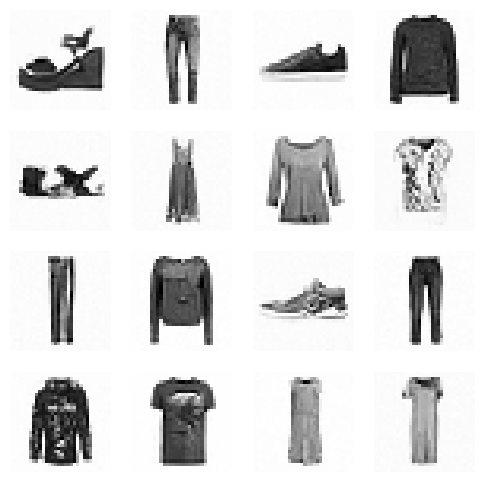

In [34]:
show_images(s[:16], imsize=1.5)

In [35]:
@inplace
def transformi2(b): b[xl] = [F.pad(TF.to_tensor(o), (2,2,2,2))*2-1 for o in b[xl]]

tds2 = dsd.with_transform(transformi2)
dls2 = DataLoaders.from_dd(tds2, bs, num_workers=fc.defaults.cpus)

cmodel = torch.load('../models/data_aug2.pkl',weights_only=False,map_location='cpu')
del(cmodel[8])
del(cmodel[7])

In [36]:
next(iter(cmodel.parameters())).device

device(type='cpu')

In [37]:
cmodel = cmodel.to(def_device)

In [38]:
next(iter(cmodel.parameters())).device

device(type='cuda', index=0)

In [39]:
xb2,_ = next(iter(dls2.train))

In [40]:
from miniai.fid import ImageEval

In [41]:
ie = ImageEval(cmodel, dls2, cbs=[DeviceCB()])

In [42]:
ie.fid(s)

30.0986328125

In [43]:
s.min(),s.max()

(tensor(-1.0548), tensor(1.3463))

In [44]:
ie.fid(xb2)  # it is -1 and 1

31.553955078125

In [45]:
ie.fid(xb*2) # it was -0.5 to 0.5 -> (*2)

35.874755859375

# Skip sampling
- not running model at every step

In [46]:
@torch.no_grad()
def sample_skip(model, sz):
    ps = next(model.parameters())
    x_t = torch.randn(sz).to(ps)
    preds = []
    for t in reversed(range(n_steps)):
        t_batch = torch.full((x_t.shape[0],), t, device=ps.device, dtype=torch.long)
        z = (torch.randn(x_t.shape) if t > 0 else torch.zeros(x_t.shape)).to(ps)
        ᾱ_t1 = alphabar[t-1]  if t > 0 else torch.tensor(1)
        b̄_t = 1-alphabar[t]
        b̄_t1 = 1-ᾱ_t1
        if t%3==0 or t<50: noise = model((x_t, t_batch)) # <-- here it is
        x_0_hat = ((x_t - b̄_t.sqrt() * noise)/alphabar[t].sqrt())
        x_t = x_0_hat * ᾱ_t1.sqrt()*(1-alpha[t])/b̄_t + x_t * alpha[t].sqrt()*b̄_t1/b̄_t + sigma[t]*z
        preds.append(x_t.cpu().float())
    return preds

In [47]:
%%time
samples = sample_skip(model, (n_samples, 1, 32, 32))

CPU times: user 1min 53s, sys: 848 ms, total: 1min 54s
Wall time: 1min 54s


In [48]:
s = (samples[-1]*2)#.clamp(-1,1)

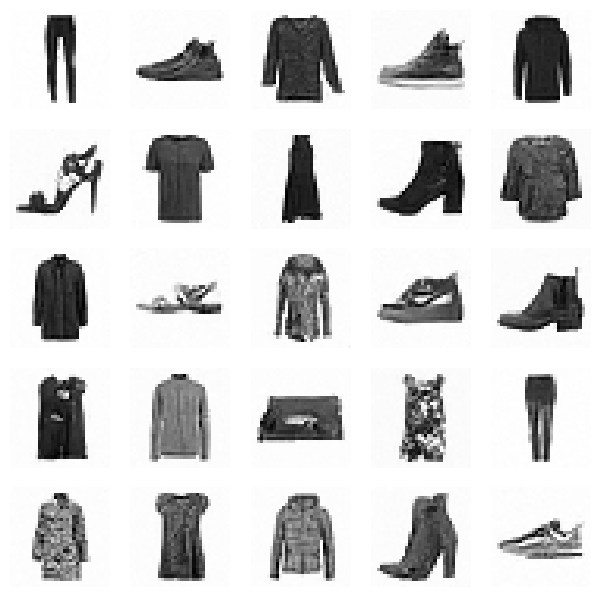

In [49]:
show_images(s[:25], imsize=1.5)

In [50]:
ie.fid(s)

49.19482421875

In [51]:
@torch.no_grad()
def sample2(model, sz):
    ps = next(model.parameters())
    x_t = torch.randn(sz).to(ps)
    sample_at = {t for t in range(n_steps) if (t+101)%((t+101)//100)==0} # <-- here
    preds = []
    for t in reversed(range(n_steps)):
        t_batch = torch.full((x_t.shape[0],), t, device=ps.device, dtype=torch.long)
        z = (torch.randn(x_t.shape) if t > 0 else torch.zeros(x_t.shape)).to(ps)
        ᾱ_t1 = alphabar[t-1]  if t > 0 else torch.tensor(1)
        b̄_t = 1-alphabar[t]
        b̄_t1 = 1-ᾱ_t1
        if t in sample_at: noise = model((x_t, t_batch))
        x_0_hat = ((x_t - b̄_t.sqrt() * noise)/alphabar[t].sqrt())
        x_t = x_0_hat * ᾱ_t1.sqrt()*(1-alpha[t])/b̄_t + x_t * alpha[t].sqrt()*b̄_t1/b̄_t + sigma[t]*z
        if t in sample_at: preds.append(x_t.float().cpu())
    return preds

It is like at the beginning do run the model every 10t but then at the next stage  every 9 and then the next stage 8, and then at the end[last 100], it becomes like every one.

In [52]:
%%time
samples = sample2(model, (n_samples, 1, 32, 32))

CPU times: user 1min 31s, sys: 148 ms, total: 1min 31s
Wall time: 1min 31s


In [53]:
s = (samples[-1]*2)#.clamp(-1,1)

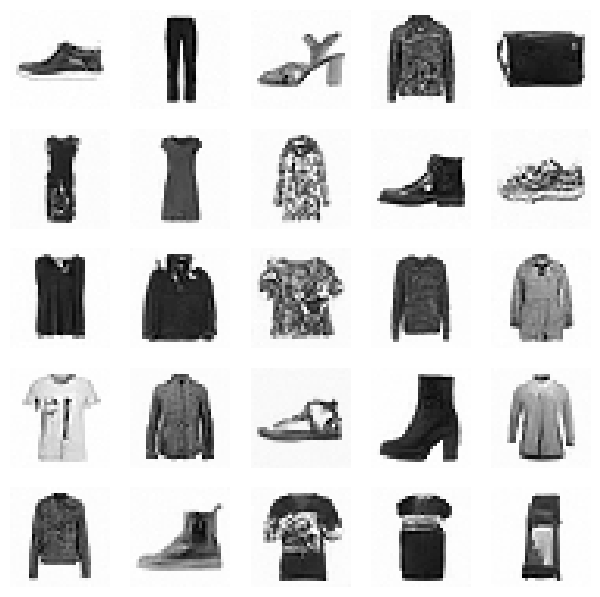

In [54]:
show_images(s[:25], imsize=1.5)

In [55]:
ie.fid(s)

49.91259765625